# Feature Construction

Raw columns are rarely the best inputs. **Feature construction** creates new features from existing ones: sums, ratios, differences, ages, interactions and polynomial terms. Good constructed features encode **domain knowledge** that a model would otherwise need much more data to discover.

**After this lesson you can:**

1. Build domain features: totals, ratios, ages and flags.
2. Create interactions and polynomial features, and control their number.
3. Measure the gain of each feature group with cross-validation.
4. Avoid typical mistakes (leakage, division by zero, redundant features).

**Data:** Ames Housing.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
RNG = 42

QUALITY = ["Very_Poor", "Poor", "Fair", "Below_Average", "Average", "Above_Average", "Good", "Very_Good", "Excellent", "Very_Excellent"]
CONDITION = ["Poor", "Fair", "Typical", "Good", "Excellent"]                 # Exter_Qual, Kitchen_Qual, ...

from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

ames = datasets.ames()
ames = ames[ames["Gr_Liv_Area"] <= 4000].reset_index(drop=True)
y = ames["Sale_Price"]
base_cols = ["Gr_Liv_Area", "Total_Bsmt_SF", "First_Flr_SF", "Second_Flr_SF", "Garage_Area", "Lot_Area", "Year_Built",
             "Year_Remod_Add", "Year_Sold", "Full_Bath", "Half_Bath", "Bsmt_Full_Bath", "Bsmt_Half_Bath", "TotRms_AbvGrd",
             "Fireplaces", "Wood_Deck_SF", "Open_Porch_SF", "Enclosed_Porch", "Screen_Porch"]
qual = ames["Overall_Qual"].map({q: i for i, q in enumerate(QUALITY)})

## 1. Domain Features

| Feature | Formula | Idea |
| :--- | :--- | :--- |
| total area | above-ground + basement | buyers think in total space |
| house age at sale | `Year_Sold - Year_Built` | age matters more than the build year |
| years since remodel | `Year_Sold - Year_Remod_Add` | renovations reset wear |
| remodelled flag | `Year_Remod_Add > Year_Built` | was the house ever renovated? |
| total bathrooms | full + 0.5 × half (incl. basement) | one number for bathrooms |
| porch area | sum of all porch types | many sparse columns into one |
| lot coverage | living area / lot area | dense vs spacious plots |

In [2]:
def domain_features(df: pd.DataFrame) -> pd.DataFrame:
    out = pd.DataFrame(index=df.index)
    out["total_sf"] = df["Gr_Liv_Area"] + df["Total_Bsmt_SF"]
    out["age_at_sale"] = df["Year_Sold"] - df["Year_Built"]
    out["years_since_remodel"] = df["Year_Sold"] - df["Year_Remod_Add"]
    out["remodelled"] = (df["Year_Remod_Add"] > df["Year_Built"]).astype(int)
    out["total_baths"] = df["Full_Bath"] + 0.5 * df["Half_Bath"] + df["Bsmt_Full_Bath"] + 0.5 * df["Bsmt_Half_Bath"]
    out["porch_sf"] = df[["Wood_Deck_SF", "Open_Porch_SF", "Enclosed_Porch", "Screen_Porch"]].sum(axis=1)
    out["lot_coverage"] = df["Gr_Liv_Area"] / df["Lot_Area"].clip(lower=1)        # clip avoids division by zero
    out["has_second_floor"] = (df["Second_Flr_SF"] > 0).astype(int)
    return out

dom = domain_features(ames)
corr = pd.concat([dom, ames[["Gr_Liv_Area", "Year_Built"]]], axis=1).corrwith(np.log(y)).sort_values(ascending=False)
print("correlation with log(price):\n", corr.round(3).to_string())

correlation with log(price):
 total_sf               0.814
Gr_Liv_Area            0.711
total_baths            0.666
Year_Built             0.617
porch_sf               0.385
has_second_floor       0.100
lot_coverage          -0.001
remodelled            -0.092
years_since_remodel   -0.590
age_at_sale           -0.617


`total_sf` correlates more strongly with price than living area alone, and `age_at_sale` is as informative as `Year_Built` but easier to interpret and stable across years.

## 2. Measure the Gain, Feature Group by Feature Group

Each step adds a group of features to a regularised linear model on log price (Ridge with built-in cross-validated regularisation), and to a gradient-boosting model, and records the cross-validated RMSE in dollars.

In [3]:
cv = KFold(5, shuffle=True, random_state=RNG)

def rmse(X, model):
    m = TransformedTargetRegressor(regressor=model, func=np.log, inverse_func=np.exp)
    return -cross_val_score(m, X, y, cv=cv, scoring="neg_root_mean_squared_error").mean()

linear = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30)))
gbm = HistGradientBoostingRegressor(random_state=RNG)
sets = {
    "raw columns": ames[base_cols],
    "+ overall quality (ordinal)": ames[base_cols].assign(qual=qual),
    "+ domain features": pd.concat([ames[base_cols].assign(qual=qual), dom], axis=1),
}
steps = pd.DataFrame({name: {"Ridge (log price)": rmse(X, linear), "Gradient boosting": rmse(X, gbm)} for name, X in sets.items()}).T
steps.round(0)

,Ridge (log price),Gradient boosting
raw columns,28717.0,25423.0
+ overall quality (ordinal),24165.0,23557.0
+ domain features,23540.0,23501.0


## 3. Interactions and Polynomial Terms

An **interaction** lets the effect of one feature depend on another: an extra square foot is worth more in a high-quality house. `PolynomialFeatures(degree=2)` creates all squares and pairwise products, which grows quickly: $p$ features give $p(p+3)/2$ columns.

In [4]:
small = pd.concat([ames[["Gr_Liv_Area", "Total_Bsmt_SF", "Garage_Area"]], dom[["total_sf", "age_at_sale", "total_baths"]]], axis=1).assign(qual=qual)
for p in [5, 10, 20, 40]:
    print(f"{p} features -> {PolynomialFeatures(2, include_bias=False).fit(np.zeros((1, p))).n_output_features_} columns after degree 2")

X_int = small.assign(qual_x_sf=small["qual"] * small["total_sf"])
X_poly = pd.DataFrame(PolynomialFeatures(2, include_bias=False).fit_transform(small), index=small.index)
print(f"\nRidge RMSE: base {rmse(small, linear):,.0f} | + one designed interaction (quality x total_sf) {rmse(X_int, linear):,.0f} "
      f"| all {X_poly.shape[1]} degree-2 terms {rmse(X_poly, linear):,.0f}")

5 features -> 20 columns after degree 2
10 features -> 65 columns after degree 2
20 features -> 230 columns after degree 2
40 features -> 860 columns after degree 2



Ridge RMSE: base 26,681 | + one designed interaction (quality x total_sf) 26,720 | all 35 degree-2 terms 26,316


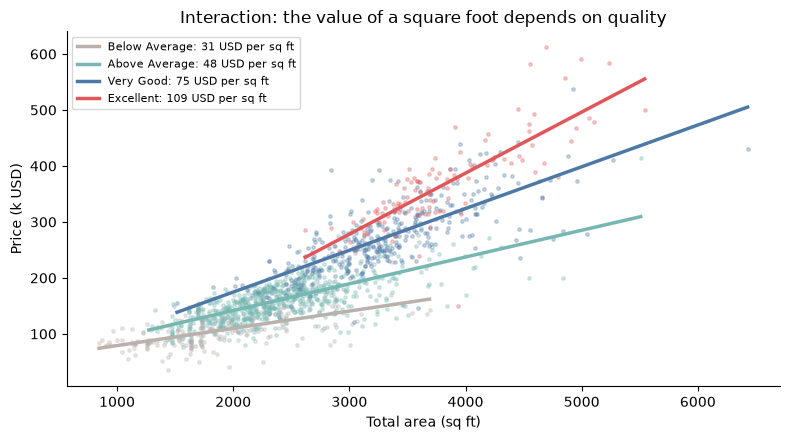

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for q, c in zip([3, 5, 7, 8], ["#BAB0AC", "#76B7B2", "#4E79A7", "#E15759"]):
    part = small[small["qual"] == q]
    b = np.polyfit(part["total_sf"], y[part.index] / 1000, 1)
    xs = np.linspace(part["total_sf"].min(), part["total_sf"].max(), 10)
    ax.scatter(part["total_sf"], y[part.index] / 1000, s=6, alpha=0.3, color=c)
    ax.plot(xs, np.polyval(b, xs), color=c, lw=2.5, label=f"{QUALITY[q].replace('_', ' ')}: {1000 * b[0]:.0f} USD per sq ft")
ax.set(xlabel="Total area (sq ft)", ylabel="Price (k USD)", title="Interaction: the value of a square foot depends on quality")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Surprise: the designed interaction does **not** help this model. The model predicts **log** price, and a log turns the multiplicative effect of quality and size (the chart above, in dollars) into an additive one, which the linear model already captures. All degree-2 terms improve the RMSE by only about 1.4 %, with 35 columns instead of 7 that are much harder to explain. Always measure an "obvious" feature before you keep it. Gradient-boosting models learn interactions automatically, which is one reason they perform well on tabular data (M16).

## 4. Pitfalls

| Pitfall | Example | Fix |
| :--- | :--- | :--- |
| leakage | "price per sq ft" uses the target | never build features from the target (Lesson 09) |
| division by zero | ratio with a zero denominator | `clip`, or add a small constant, or a flag |
| redundancy | total area **and** all its parts in a linear model | regularisation, or keep the most useful version |
| feature explosion | all polynomial terms of 80 columns | design a few, select (Lesson 08) |
| train/production skew | a feature computed differently in production | one function used in both places (Lessons 10, 16) |

*Insight: Constructed features are domain knowledge written as code: totals, ratios, ages and a few meaningful interactions often beat hundreds of automatic terms. Add them in groups and keep only what improves cross-validated performance.*

## Real-World Use Case or Analogy

Feature construction is like an **experienced estate agent's checklist**: they do not look at 80 separate columns, they think in "total space", "age of the house", "renovated or not" and "quality of the finish". Giving the model these concepts saves it from having to rediscover them.

In fraud detection, the most powerful features are constructed: "number of transactions in the last hour", "distance from the usual location", "amount relative to the customer's average".